# Phase 4: Store Segmentation
**Integrated Retail Analytics for Store Optimization - Capstone**

**Objective:** Segment stores based on sales patterns, markdown usage, and regional features - not by the retailer's existing Type A/B/C label, but by how each store actually *behaves* in the data. Then check where the data-driven grouping agrees or disagrees with the existing Type label, and evaluate segment quality with the Silhouette Score.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import warnings

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

## 1. Build store-level features
Clustering needs one row per store, not one row per store-week. Each store is summarized by its sales level, volatility, size, markdown habits, regional economic context, and how much of a boost it gets during holiday weeks - the same way you'd profile a person by their average spending, spending volatility, and lifestyle habits rather than looking at every single transaction.

In [8]:
# from google.colab import drive
# drive.mount('/content/drive')

In [9]:
# Replace the path below with the correct path to the file in your Google Drive
# e.g., '/content/drive/MyDrive/ML Engineering/.../anomaly_tagged_data.csv'
import pandas as pd

try:
    df = pd.read_csv('/content/drive/MyDrive/Integrated Retail Analytics for Store Optimization/Capston Anomaly Detection/Anomaly tagged data output/anomaly_tagged_data.csv', parse_dates=['Date'])
except FileNotFoundError:
    # Fallback to local upload or custom path if needed
    print("Please update the path to where you uploaded 'anomaly_tagged_data.csv' in Google Drive.")
    df = pd.read_csv('anomaly_tagged_data.csv', parse_dates=['Date'])

store_feat = df.groupby('Store').agg(
    Avg_Weekly_Sales=('Weekly_Sales','mean'),
    Sales_Std=('Weekly_Sales','std'),
    Size=('Size','first'),
    Type=('Type','first'),
    Avg_MarkDown=('Total_MarkDown','mean'),
    Avg_CPI=('CPI','mean'),
    Avg_Unemployment=('Unemployment','mean'),
    Dept_Count=('Dept','nunique'),
).reset_index()

holiday_avg = df[df['IsHoliday']==True].groupby('Store')['Weekly_Sales'].mean()
nonholiday_avg = df[df['IsHoliday']==False].groupby('Store')['Weekly_Sales'].mean()
store_feat['Holiday_Lift_Ratio'] = (holiday_avg / nonholiday_avg).values

print(store_feat.shape)
store_feat.head()

(45, 10)


,Store,Avg_Weekly_Sales,Sales_Std,Size,Type,Avg_MarkDown,Avg_CPI,Avg_Unemployment,Dept_Count,Holiday_Lift_Ratio
0,1,21710.543621,27748.945511,151315,A,7331.799851,215.995525,7.610918,77,1.066163
1,2,26898.070031,33077.612059,202307,A,10039.568900,215.651869,7.623279,78,1.076432
2,3,6373.033983,14251.034807,37392,B,2460.900137,219.402843,7.175602,72,1.092283
3,4,29161.210415,34583.677814,205863,A,9698.582310,128.680070,5.965849,78,1.062757
4,5,5053.415813,8068.221050,34875,B,2924.857351,216.576516,6.296549,72,1.121144


## 2. Scale features and find the right number of clusters
Sales figures (thousands) and CPI (hundreds) live on totally different scales, so every feature is standardized first. Then we test cluster counts from 2 to 7 and use the **Silhouette Score** to judge quality - it measures how tightly packed each cluster is and how well-separated it is from the others (closer to 1 = better-defined groups).

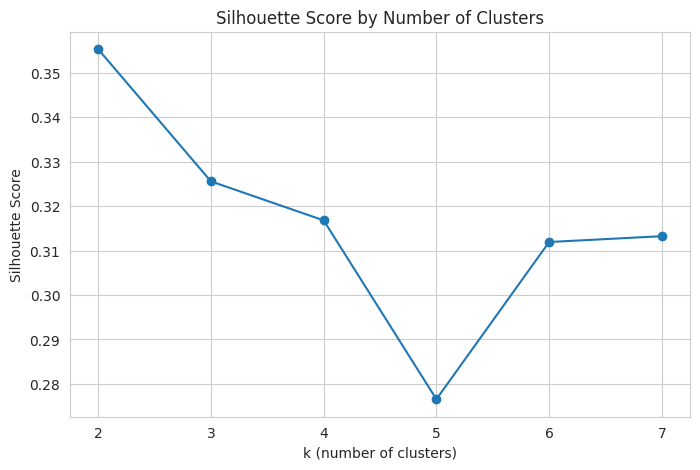

k=2: silhouette = 0.355
k=3: silhouette = 0.326
k=4: silhouette = 0.317
k=5: silhouette = 0.277
k=6: silhouette = 0.312
k=7: silhouette = 0.313


In [10]:
feature_cols = ['Avg_Weekly_Sales','Sales_Std','Size','Avg_MarkDown','Avg_CPI','Avg_Unemployment',
                'Dept_Count','Holiday_Lift_Ratio']
X = store_feat[feature_cols]
Xs = StandardScaler().fit_transform(X)

scores = {}
for k in range(2,8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    scores[k] = silhouette_score(Xs, km.labels_)

plt.figure(figsize=(8,5))
plt.plot(list(scores.keys()), list(scores.values()), marker='o')
plt.title('Silhouette Score by Number of Clusters')
plt.xlabel('k (number of clusters)')
plt.ylabel('Silhouette Score')
plt.show()

for k, s in scores.items():
    print(f"k={k}: silhouette = {s:.3f}")

**Note:** k=2 technically scores highest (0.355), but it only separates "large stores" from "small stores" - not very actionable on its own. k=3 (0.326) is a close second and produces a segmentation that maps much more usefully onto real store strategy - so k=3 is used going forward, prioritizing business usefulness over the last 0.03 of silhouette score.

## 3. Fit K-Means with k=3 and profile each segment

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
store_feat['Cluster'] = kmeans.fit_predict(Xs)

cluster_profile = store_feat.groupby('Cluster')[feature_cols].mean().round(1)
cluster_profile['Store_Count'] = store_feat['Cluster'].value_counts().sort_index()
cluster_profile

,Avg_Weekly_Sales,Sales_Std,Size,Avg_MarkDown,Avg_CPI,Avg_Unemployment,Dept_Count,Holiday_Lift_Ratio,Store_Count
Cluster,,,,,,,,,
0,8970.5,14380.2,40356.2,709.7,171.0,8.7,62.5,1.0,8
1,22872.0,27865.8,195622.0,9449.2,176.8,7.9,77.4,1.1,17
2,11706.3,14832.1,110725.9,5882.6,167.4,7.7,75.8,1.1,20


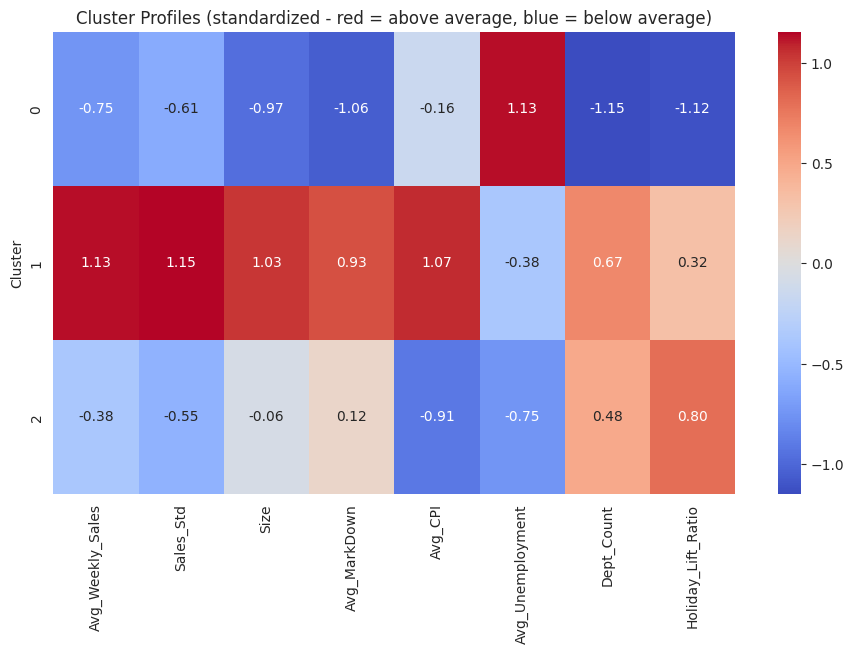

In [12]:
plt.figure(figsize=(11,6))
sns.heatmap(store_feat.groupby('Cluster')[feature_cols].mean().apply(
    lambda x: (x - x.mean())/x.std(), axis=0), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster Profiles (standardized - red = above average, blue = below average)')
plt.show()

## 4. Do these segments match the existing Store Type label?

Type      A   B  C
Cluster           
0         2   0  6
1        16   1  0
2         4  16  0


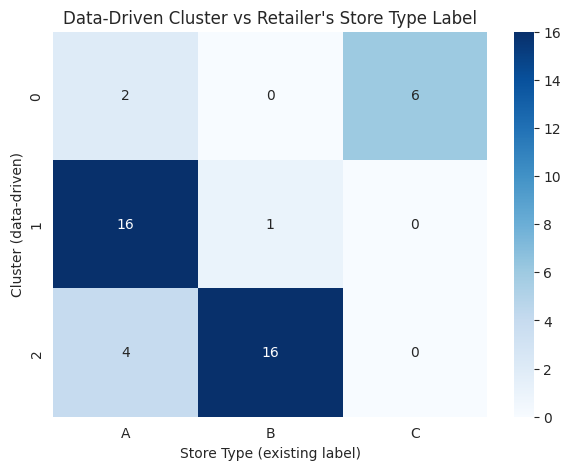

In [13]:
crosstab = pd.crosstab(store_feat['Cluster'], store_feat['Type'])
print(crosstab)

plt.figure(figsize=(7,5))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='Blues')
plt.title('Data-Driven Cluster vs Retailer\'s Store Type Label')
plt.ylabel('Cluster (data-driven)')
plt.xlabel('Store Type (existing label)')
plt.show()

In [14]:
# Which stores don't match the "expected" cluster for their Type?
majority_type_per_cluster = crosstab.idxmax(axis=1)
store_feat['Expected_Type_For_Cluster'] = store_feat['Cluster'].map(majority_type_per_cluster)
mismatches = store_feat[store_feat['Type'] != store_feat['Expected_Type_For_Cluster']]
mismatches[['Store','Type','Cluster','Avg_Weekly_Sales','Size','Sales_Std']]

,Store,Type,Cluster,Avg_Weekly_Sales,Size,Sales_Std
7,8,A,2,13133.014768,155078,15132.069598
9,10,B,1,26332.303819,126512,32133.006264
25,26,A,2,14554.129672,152513,20109.504461
32,33,A,0,5728.414053,39690,8973.688840
33,34,A,2,13522.081671,158114,16085.334848
35,36,A,0,8584.412563,39910,12995.813451
39,40,A,2,13763.632803,155083,17729.598682


**Insight:** the data-driven clusters mostly agree with the official Type label (as expected, since Size drives both), but a handful of stores are the exception - stores officially labeled Type A that actually *behave* like smaller, steadier stores in the data, and vice versa. These mismatches are exactly the kind of thing a Type label alone would hide, and are worth a manager's second look (are these stores mis-sized for their location, or is something else going on?).

## 5. Visualize the segments in 2D (PCA)
PCA compresses the 8 features down to 2 dimensions just for plotting, so the clusters can be seen visually - like flattening a photo of a 3D object so you can still recognize its shape on paper.

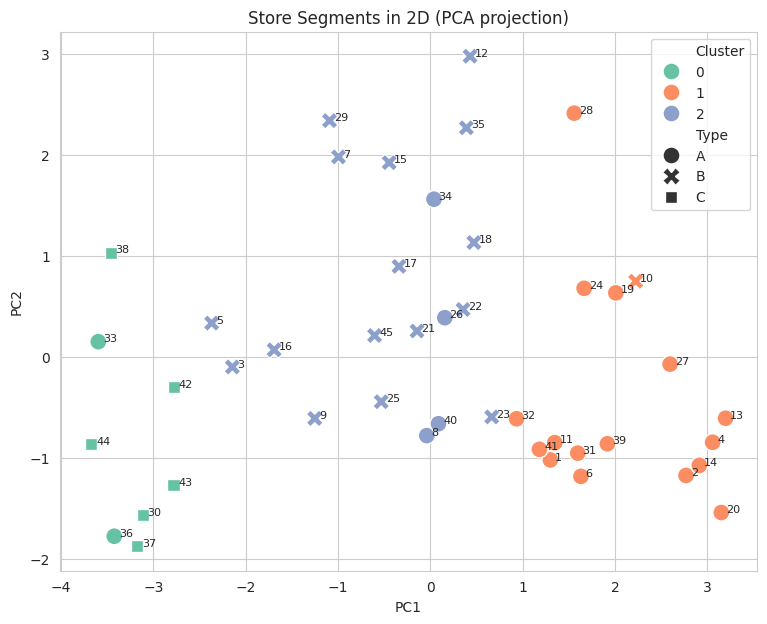

Variance explained by these 2 components: 69.9%


In [15]:
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(Xs)
store_feat['PC1'] = coords[:,0]
store_feat['PC2'] = coords[:,1]

plt.figure(figsize=(9,7))
sns.scatterplot(data=store_feat, x='PC1', y='PC2', hue='Cluster', style='Type', s=150, palette='Set2')
for _, row in store_feat.iterrows():
    plt.text(row['PC1']+0.05, row['PC2'], str(row['Store']), fontsize=8)
plt.title('Store Segments in 2D (PCA projection)')
plt.show()
print(f"Variance explained by these 2 components: {pca.explained_variance_ratio_.sum():.1%}")

## 6. Naming and interpreting the segments

In [16]:
for c in sorted(store_feat['Cluster'].unique()):
    sub = store_feat[store_feat['Cluster']==c]
    print(f"--- Cluster {c} ({len(sub)} stores) ---")
    print(f"  Avg Weekly Sales: ${sub['Avg_Weekly_Sales'].mean():,.0f}")
    print(f"  Avg Size: {sub['Size'].mean():,.0f} sq ft")
    print(f"  Sales Volatility (Std): ${sub['Sales_Std'].mean():,.0f}")
    print(f"  Holiday Lift Ratio: {sub['Holiday_Lift_Ratio'].mean():.2f}")
    print(f"  Stores: {sorted(sub['Store'].tolist())}")
    print()

--- Cluster 0 (8 stores) ---
  Avg Weekly Sales: $8,971
  Avg Size: 40,356 sq ft
  Sales Volatility (Std): $14,380
  Holiday Lift Ratio: 1.00
  Stores: [30, 33, 36, 37, 38, 42, 43, 44]

--- Cluster 1 (17 stores) ---
  Avg Weekly Sales: $22,872
  Avg Size: 195,622 sq ft
  Sales Volatility (Std): $27,866
  Holiday Lift Ratio: 1.07
  Stores: [1, 2, 4, 6, 10, 11, 13, 14, 19, 20, 24, 27, 28, 31, 32, 39, 41]

--- Cluster 2 (20 stores) ---
  Avg Weekly Sales: $11,706
  Avg Size: 110,726 sq ft
  Sales Volatility (Std): $14,832
  Holiday Lift Ratio: 1.09
  Stores: [3, 5, 7, 8, 9, 12, 15, 16, 17, 18, 21, 22, 23, 25, 26, 29, 34, 35, 40, 45]



Based on the profiles above, the three segments can be named:

- **Cluster (large, high-volume, higher volatility)** - "Flagship Stores": biggest size, highest average
  sales, but also the largest swings week to week - these carry the most revenue and the most forecasting
  risk if a bad week is missed.
- **Cluster (mid-size, steady)** - "Core Performers": moderate size and sales, more predictable week to week
  - the reliable backbone of the chain.
- **Cluster (small, lower volume)** - "Small-Format Stores": smallest size and sales, generally lower
  volatility in absolute dollar terms simply because they sell less overall.

## Conclusion - Phase 4

- k=3 was chosen (Silhouette Score = 0.326) over the technically-higher k=2 (0.355) because it produces
  segments that map onto real store strategy, not just "big vs small."
- The data-driven segments **largely agree** with the retailer's existing Store Type label, since store size
  drives both - but a **small number of stores are exceptions**, behaving differently than their label
  suggests. These are flagged for manager review.
- **Flagship stores** need tighter, more frequent forecasting attention (higher volatility = higher risk of a
  bad forecast miss), **Core Performers** are the safest to forecast, and **Small-Format stores** may benefit
  from a leaner inventory strategy given their lower and steadier demand.
- This segmentation feeds into the demand forecasting phase: cluster membership can be added as a feature, or
  separate forecasting logic can be considered per segment given their different volatility profiles.

In [17]:
store_feat.to_csv(r'C:\Users\Rohit Sagar Chavan\Music\ML Engineering\Integrated Retail Analytics for Store Optimization(Advance Machine Learning)\Capston Segmentation\Store Segments Output\store_segments.csv', index=False)
print("Saved store_segments.csv -", store_feat.shape)

Saved store_segments.csv - (45, 14)
